In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Please upload your input image:")
uploaded = files.upload()
image_path = next(iter(uploaded))

Please upload your input image:


Saving test_image.jpg to test_image.jpg


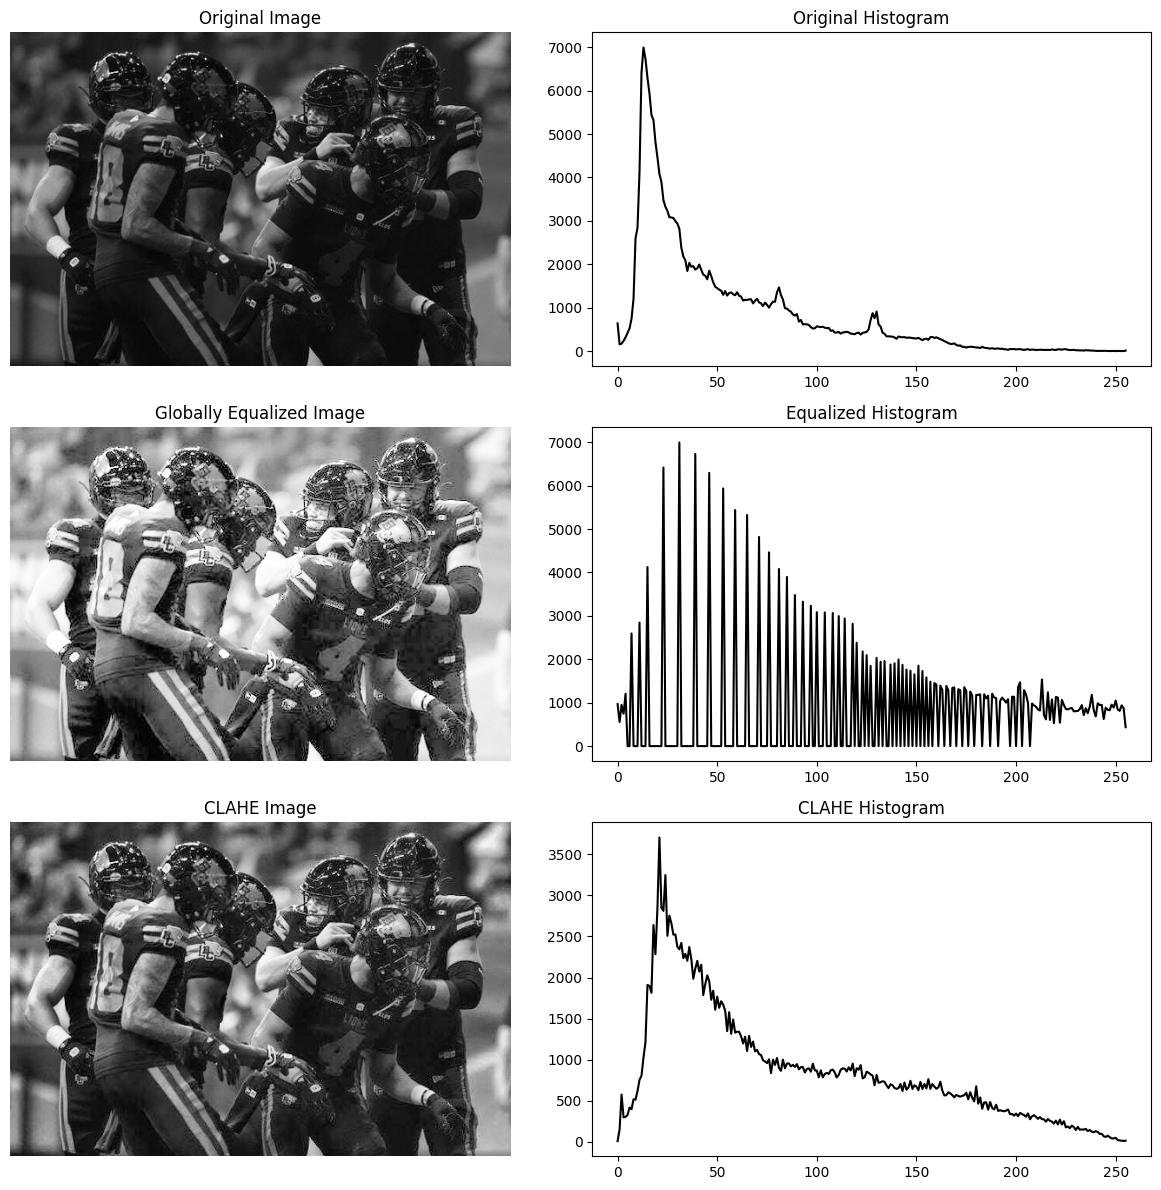

In [ ]:
# Load the image in grayscale
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found.")
else:
    # --- PART 1: Standard Histogram Equalization ---
    # Apply global histogram equalization
    img_eq = cv2.equalizeHist(img)

    # Calculate histograms
    hist_original = cv2.calcHist([img], [0], None, [256], [0, 256])
    hist_eq = cv2.calcHist([img_eq], [0], None, [256], [0, 256])

    # --- PART 2: Contrast Adjustment (Linear and CLAHE) ---
    # Linear Contrast Adjustment (Contrast Stretching)
    img_stretched = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

    # Adaptive Histogram Equalization (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    img_clahe = clahe.apply(img)

    hist_clahe = cv2.calcHist([img_clahe], [0], None, [256], [0, 256])

    # --- VISUALIZATION ---
    # Plotting Images and Histograms side-by-side
    fig, axs = plt.subplots(3, 2, figsize=(12, 12))

    # Original Image & Histogram
    axs[0, 0].imshow(img, cmap='gray')
    axs[0, 0].set_title('Original Image')
    axs[0, 0].axis('off')
    axs[0, 1].plot(hist_original, color='black')
    axs[0, 1].set_title('Original Histogram')

    # Global Equalization
    axs[1, 0].imshow(img_eq, cmap='gray')
    axs[1, 0].set_title('Globally Equalized Image')
    axs[1, 0].axis('off')
    axs[1, 1].plot(hist_eq, color='black')
    axs[1, 1].set_title('Equalized Histogram')

    # CLAHE Result
    axs[2, 0].imshow(img_clahe, cmap='gray')
    axs[2, 0].set_title('CLAHE Image')
    axs[2, 0].axis('off')
    axs[2, 1].plot(hist_clahe, color='black')
    axs[2, 1].set_title('CLAHE Histogram')

    plt.tight_layout()
    plt.show()